# COURSE: Deep Learning for Music Technology
## SECTION: Transformers for music
### EXERCISE E2: Your first music GPT (jazz edition)
#### Builds on: `DUDL_RNN_loremipsum` (same character tables, same loss, same optimizer)

**Goal.** Train a small transformer (a "mini-GPT") from scratch on **jazz solos written as text**, and *hear* it learn.

In `DUDL_RNN_loremipsum` an LSTM learned to write fake Latin one character at a time. Here we keep the same idea (characters → numbers → predict the next character) but:

* the text is **music**: jazz solos in [ABC notation](https://abcnotation.com/wiki/abc:standard:v2.1), with the chord changes;
* the `nn.LSTM` is replaced by **self-attention**: the model looks back at all previous characters at once and learns *which ones matter*.

| Part | What you do | Time |
|---|---|---|
| 1 | Load the data, read jazz ABC, build `letter2number` | 15 min |
| 2 | Read the model, count its parameters | 15 min |
| 3 | Train it (GPU) and watch the loss | 15–20 min |
| 4 | **The learning curve you can hear**: listen to 3 checkpoints | 30 min |
| 5 | Sampling: temperature, top-k, your own prompt | 30 min |
| 6 | Look inside: attention maps | 20 min |
| ★ | Code challenges (optional) | — |
| H2 | Home: sampling lab | 1.5 h |

**Before you start (Colab):** *Runtime → Change runtime type → T4 GPU*. Then run the cells from top to bottom.
Cells marked **Helper** are folded: run them, you don't need to read them (but you may!).
Look for **❓ Questions**: answer them in your notes, they are part of the exercise.

### The data: the Weimar Jazz Database

The [Weimar Jazz Database](https://jazzomat.hfm-weimar.de/dbformat/dboverview.html) (Jazzomat Research Project, HfM Weimar) contains **456 jazz solos by 78 players** (Charlie Parker, John Coltrane, Sonny Rollins, Miles Davis, Chet Baker, Michael Brecker…), transcribed note by note, with the chord changes and the form.

We take the 431 solos in 4/4 and turn **every chorus** (one time through the form of the tune: a 12-bar blues, a 32-bar AABA song…) into one ABC tune. That gives about **1,250 choruses, 860,000 characters**: as much text as a 300-page novel.

**There is no ready-made jazz dataset in ABC notation**, so the helper cell below writes it: it reads the solos from the database, rounds the rhythm to 16th notes or 8th-note triplets, writes swing 8ths straight (like on a lead sheet), and adds the chord symbols.

**Licence and ethics.** The database is free to use under the [Open Database License (ODbL)](https://opendatacommons.org/licenses/odbl/1.0/): you must credit it and share changed versions under the same licence. Three things to think about:
1. These are real improvisations by real musicians, many of them still alive.
2. A transcription is already an interpretation, and so is our conversion: we rounded the rhythm and dropped dynamics and pitch bends.
3. The player's name is part of the data (`C:` line). What does it mean to ask a model for "a solo by Charlie Parker"?

# Setup

In [1]:
### import libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import math, os, re, time, random, urllib.request

# for data visualization
import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')
from IPython.display import clear_output

In [2]:
# use the GPU if there is one (Colab: Runtime > Change runtime type > T4 GPU)
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
print(device)

mps


In [3]:
#@title Where to save your work
# Colab can disconnect at any time. Checkpoints saved to Google Drive survive that.
USE_DRIVE = True  #@param {type:"boolean"}

try:
  import google.colab
  IN_COLAB = True
except ImportError:
  IN_COLAB = False

if IN_COLAB and USE_DRIVE:
  from google.colab import drive
  drive.mount('/content/drive')
  SAVE_DIR = '/content/drive/MyDrive/music_transformers/E2'
else:
  SAVE_DIR = 'E2_files'
os.makedirs(SAVE_DIR, exist_ok=True)
print('Files will be saved in', SAVE_DIR)

Files will be saved in E2_files


In [4]:
#@title Helper 1: Weimar Jazz Database → ABC (run me, no need to read)
# Teacher-side data preparation. One ABC tune per chorus; rhythm rounded per beat to a
# 16th-note grid or an 8th-triplet grid; swing 8ths written straight; Jazzomat chord
# names (C-7, Fj7, Bb79b) rewritten as lead-sheet chords (Cm7, Fmaj7, Bb7b9).
import re, sqlite3, unicodedata
import numpy as np
import pandas as pd

TPB = 12                      # ticks per beat (quarter): LCM of 4 (16ths) and 3 (triplets)
BAR = 4 * TPB                 # 4/4 only
LEGATO_GAP = 12              # gaps shorter than this (a quarter) are closed: notes are held until the next one

# ---------------------------------------------------------------- keys & spelling
LETTERS = 'CDEFGAB'
NAT_PC = dict(C=0, D=2, E=4, F=5, G=7, A=9, B=11)
SHARP_ORDER, FLAT_ORDER = 'FCGDAEB', 'BEADGCF'
MAJOR_FIFTHS = {'C': 0, 'G': 1, 'D': 2, 'A': 3, 'E': 4, 'B': 5, 'F#': 6, 'C#': 7,
                'F': -1, 'Bb': -2, 'Eb': -3, 'Ab': -4, 'Db': -5, 'Gb': -6, 'Cb': -7}
PC_NAME = {0: 'C', 1: 'Db', 2: 'D', 3: 'Eb', 4: 'E', 5: 'F', 6: 'Gb', 7: 'G', 8: 'Ab',
           9: 'A', 10: 'Bb', 11: 'B'}
MINOR_TONIC = {0: 'C', 1: 'C#', 2: 'D', 3: 'Eb', 4: 'E', 5: 'F', 6: 'F#', 7: 'G',
               8: 'G#', 9: 'A', 10: 'Bb', 11: 'B'}


def name_to_pc(n):
    pc = NAT_PC[n[0]]
    for a in n[1:]:
        pc += {'#': 1, 'b': -1}[a]
    return pc % 12


def parse_key(k):
    """'Bb-maj' -> ('Bb', fifths); unknown / chromatic -> ('C', 0)."""
    if not k or '-' not in k:
        k = (k or '') + '-maj'
    tonic, mode = k.split('-', 1)
    if not re.fullmatch(r'[A-G][#b]?', tonic) or mode == 'chrom':
        return 'C', 0
    pc = name_to_pc(tonic)
    if mode == 'min':
        name = MINOR_TONIC[pc]
        return name + 'm', MAJOR_FIFTHS[PC_NAME[(pc + 3) % 12]]
    if mode == 'dor':
        return PC_NAME[pc] + 'dor', MAJOR_FIFTHS[PC_NAME[(pc - 2) % 12]]
    if mode == 'mix':
        return PC_NAME[pc] + 'mix', MAJOR_FIFTHS[PC_NAME[(pc + 5) % 12]]
    return PC_NAME[pc], MAJOR_FIFTHS[PC_NAME[pc]]   # maj, blues, ...


def key_signature(fifths):
    sig = {l: 0 for l in LETTERS}
    if fifths > 0:
        for l in SHARP_ORDER[:fifths]:
            sig[l] = 1
    else:
        for l in FLAT_ORDER[:-fifths]:
            sig[l] = -1
    return sig


def spelling_table(key_name, fifths):
    """pitch class -> (letter, accidental) for this key."""
    sig = key_signature(fifths)
    lead = None
    if key_name.endswith('m') and not key_name.endswith('dor'):
        tonic = key_name[:-1]
        lead = ((name_to_pc(tonic) - 1) % 12, LETTERS[(LETTERS.index(tonic[0]) - 1) % 7])
    table = {}
    for pc in range(12):
        best = None
        for l in LETTERS:
            for acc in (-1, 0, 1):
                if (NAT_PC[l] + acc) % 12 != pc:
                    continue
                if acc == sig[l]:
                    score = 0
                elif lead and pc == lead[0] and l == lead[1]:
                    score = 0.5
                elif acc == 0:
                    score = 1
                elif l + str(acc) in ('C-1', 'F-1', 'E1', 'B1'):
                    score = 5
                else:
                    score = 2 if acc == -1 else 3      # jazz: prefer flats
                if best is None or score < best[0]:
                    best = (score, l, acc)
        table[pc] = best[1:]
    return table, sig


def abc_pitch(midi, table):
    letter, acc = table[midi % 12]
    octave = (midi - acc) // 12 - 1          # MIDI 60 = C4
    s = letter if octave <= 4 else letter.lower()
    if octave > 5:
        s += "'" * (octave - 5)
    if octave < 4:
        s += ',' * (4 - octave)
    return letter, acc, s


# ---------------------------------------------------------------- chords
TENSION = {'9b': 'b9', '9': '9', '9#': '#9', '11': '11', '11#': '#11', '13': '13', '13b': 'b13'}


def chord_name(c):
    """Jazzomat chord syntax -> common lead-sheet syntax (Cm7, Fmaj7, Bb7b9, ...)."""
    if c in ('NC', ''):
        return 'N.C.' if c else ''
    m = re.fullmatch(r'([A-G][#b]?)(.*?)(?:/([A-G][#b]?))?', c)
    if not m:
        return c
    root, q, bass = m.groups()
    out = None
    alt = q.endswith('alt')
    if alt:
        q = q[:-3]
    if q.startswith('m7b5'):
        out, rest = 'm7b5', q[4:]
    elif q.startswith('o7'):
        out, rest = 'dim7', q[2:]
    elif q.startswith('o'):
        out, rest = 'dim', q[1:]
    else:
        tri = ''
        if q.startswith('-'):
            tri, q = 'm', q[1:]
        elif q.startswith('+'):
            tri, q = '+', q[1:]
        elif q.startswith('sus'):
            tri, q = 'sus', q[3:]
        sev = ''
        for s in ('j7', '7', '69', '6'):
            if q.startswith(s):
                sev, q = s, q[len(s):]
                break
        tens = re.findall(r'(9b|9#|9|11#|11|13b|13)', q)
        tens = [TENSION[t] for t in tens]
        if tri == 'sus':
            base = {'': 'sus4', '7': '7sus4'}.get(sev, sev + 'sus4')
            if sev == '7' and '13' in tens:
                base = '13sus4'
            elif sev == '7' and '9' in tens:
                base = '9sus4'
            out = base
        elif tri == '+':
            out = 'aug' if sev == '' else '7#5'
        else:
            if sev == 'j7':
                sev = 'maj7'
            if sev in ('7', 'maj7') and tens:
                # 9 / 13 upgrade the chord name, altered tensions are appended
                plain = [t for t in tens if t in ('9', '11', '13')]
                altered = [t for t in tens if t not in plain]
                top = plain[-1] if plain else None
                if top:
                    sev = sev.replace('7', top) if not (top == '11' and tri == '') else sev + '#11'
                sev += ''.join(altered)
            elif sev == '' and tens:
                sev = 'add9' if '9' in tens else ''
            out = tri + sev
    if alt:
        out = out.replace('7', '7alt', 1) if '7' in out else out + '7alt'
    name = root + out
    if bass:
        name += '/' + bass
    return name


# ---------------------------------------------------------------- quantisation
def quantise_solo(mel, beats):
    """Return a monophonic list of [on_tick, off_tick, midi]; tick 0 = first bar of the solo."""
    bar0 = min(mel.bar.min(), beats.bar.min())
    gidx_beats = (beats.bar - bar0) * 4 + (beats.beat - 1)
    bt, bi = beats.onset.values, gidx_beats.values.astype(float)
    order = np.argsort(bt)
    bt, bi = bt[order], bi[order]
    last_dur = np.median(np.diff(bt[-9:])) if len(bt) > 2 else 0.5

    def time_to_beat(t):
        if t <= bt[-1]:
            return float(np.interp(t, bt, bi))
        return bi[-1] + (t - bt[-1]) / last_dur

    g = (mel.bar.values - bar0) * 4 + (mel.beat.values - 1)
    frac = (mel.tatum.values - 1) / mel.division.values
    on = g + frac
    off = np.array([time_to_beat(t) for t in (mel.onset + mel.duration).values])
    off = np.maximum(off, on + 0.05)
    pitch = mel.pitch.round().astype(int).values

    # choose the grid of every beat from the onsets that fall in it
    nbeats = int(np.ceil(max(off.max(), on.max()))) + 2
    errs = np.zeros((nbeats, 2))
    for o in on:
        b, f = int(np.floor(o)), o - np.floor(o)
        errs[b, 0] += abs(f * 4 - round(f * 4)) / 4
        errs[b, 1] += abs(f * 3 - round(f * 3)) / 3
    triplet = errs[:, 1] < errs[:, 0] - 0.02
    # a "triplet" beat with onsets only on 1 and 3 of the triplet (long-short) is a pair of
    # swung 8ths: write it straight, as on a lead sheet (swing is added back at playback)
    middle = np.zeros(nbeats, bool)
    for o in on:
        b, f = int(np.floor(o)), o - np.floor(o)
        if round(f * 3) == 1:
            middle[b] = True
    swing = triplet & ~middle
    triplet &= middle

    def snap(x):
        b = int(np.floor(x))
        f = x - b
        if triplet[b]:
            return b * TPB + int(round(f * 3)) * 4
        if swing[b]:
            return b * TPB + (0, 3, 6, 12)[int(round(f * 3))]
        return b * TPB + int(round(f * 4)) * 3

    notes = []
    for o, e, p in zip(on, off, pitch):
        notes.append([snap(o), snap(e), p, e - o])
    notes.sort(key=lambda n: (n[0], -n[3]))
    clean = []
    for n in notes:                                  # one note per onset (keep the longest)
        if clean and clean[-1][0] == n[0]:
            continue
        clean.append(n)
    for i, n in enumerate(clean):
        nxt = clean[i + 1][0] if i + 1 < len(clean) else None
        if n[1] <= n[0]:
            b = n[0] // TPB
            n[1] = n[0] + (4 if triplet[b] else 3)
        if nxt is not None:
            if n[1] > nxt or nxt - n[1] < LEGATO_GAP:  # overlap, or a short gap
                n[1] = nxt
    return [n[:3] for n in clean]


# ---------------------------------------------------------------- ABC writing
DUR_BIN = {3: '/', 6: '', 9: '3/', 12: '2', 18: '3', 24: '4', 36: '6', 48: '8'}
MERGEABLE = {6, 9, 12, 18, 24, 36, 48}


def bar_to_abc(bar_events, chords_at, table, sig):
    """bar_events: list of (start, end, midi|None, tie_out) in ticks, covering 0..BAR.
    chords_at: {beat_index: chord_name}. Returns the bar as ABC text (no bar line)."""
    # 1. split events at beat boundaries
    atoms = []
    for (s, e, p, to) in bar_events:
        b = s // TPB
        while s < e:
            be = min(e, (b + 1) * TPB)
            atoms.append(dict(beat=b, s=s, e=be, p=p, to=(p is not None) and (to if be == e else True)))
            s, b = be, b + 1
    # 2. grid of every beat: triplet if some boundary is not on the 16th grid
    for a in atoms:
        a['tri'] = False
    for b in range(4):
        bat = [a for a in atoms if a['beat'] == b]
        if any(a['s'] % 3 or a['e'] % 3 for a in bat):
            for a in bat:
                a['tri'] = True
    # 3. group atoms: one group per beat, but merge a tied note / rest across the beat
    #    boundary when the result is a simple duration starting on an 8th
    groups = []
    for a in atoms:
        first_in_beat = a['s'] == a['beat'] * TPB
        prev = groups[-1][-1] if groups else None
        if first_in_beat:
            can = (prev is not None and a['beat'] not in chords_at
                   and not prev['tri'] and not a['tri']
                   and prev['p'] == a['p'] and (prev['p'] is None or prev['to'])
                   and prev['s'] % 6 == 0
                   and (a['e'] - prev['s']) in MERGEABLE)
            if can:
                prev['e'], prev['to'] = a['e'], a['to']
                continue
            groups.append([a])
        else:
            groups[-1].append(a)
    # 4. write
    state = {}                     # accidentals last until the bar line (per letter + octave)
    out = []
    for grp in groups:
        txt = ''
        tri = grp[0]['tri']
        if tri:
            units = [(a['e'] - a['s']) // 4 for a in grp]
            txt += '(3' if units == [1, 1, 1] else '(3:2:%d' % len(units)
        for a in grp:
            b = a['s'] // TPB
            if a['s'] % TPB == 0 and b in chords_at:
                txt += '"%s"' % chords_at[b]
            ln = a['e'] - a['s']
            d = {4: '', 8: '2'}[ln] if tri else DUR_BIN[ln]
            if a['p'] is None:
                txt += 'z' + d
            else:
                letter, acc, s = abc_pitch(a['p'], table)
                if acc != state.get(s, sig[letter]):
                    txt += {-1: '_', 0: '=', 1: '^'}[acc]
                    state[s] = acc
                txt += s + d + ('-' if a['to'] else '')
        out.append(txt)
    return ' '.join(out)


def solo_to_records(mel, bts, key, min_notes=8):
    """One solo -> list of ABC bodies, one per chorus."""
    notes = quantise_solo(mel, bts)
    bar0 = min(mel.bar.min(), bts.bar.min())
    key_name, fifths = parse_key(key)
    table, sig = spelling_table(key_name, fifths)

    chords = {}
    for r in bts.itertuples():
        if r.chord:
            chords[(r.bar - bar0, r.beat - 1)] = chord_name(r.chord)
    chorus_of_bar = {r.bar - bar0: max(1, r.chorus_id) for r in bts[bts.beat == 1].itertuples()}
    counts = pd.Series(chorus_of_bar).value_counts()
    last = max(counts.index)
    if counts[last] < 4 and last > 1:          # short tail -> previous chorus
        chorus_of_bar = {k: (last - 1 if v == last else v) for k, v in chorus_of_bar.items()}

    timeline = {}                              # bar -> [[s, e, p, tie_in, tie_out], ...]
    for (s, e, p) in notes:
        first = True
        while s < e:
            bar = s // BAR
            be = min(e, (bar + 1) * BAR)
            timeline.setdefault(bar, []).append([s - bar * BAR, be - bar * BAR, p, not first, be < e])
            s, first = be, False

    records, current_chord = [], None
    for ch in sorted(set(chorus_of_bar.values())):
        bars = sorted(b for b, c in chorus_of_bar.items() if c == ch)
        filled_bars, chord_bars = [], []
        for i, bar in enumerate(bars):
            evs = sorted(timeline.get(bar, []))
            filled, t = [], 0
            for s, e, p, ti, to in evs:
                if s > t:
                    filled.append((t, s, None, False))
                if i == 0 and ti:              # a note tied into a new record becomes a rest
                    p = None
                filled.append((s, e, p, to and i < len(bars) - 1))
                t = e
            if t < BAR:
                filled.append((t, BAR, None, False))
            ca = {bt: chords[(bar, bt)] for bt in range(4) if (bar, bt) in chords}
            filled_bars.append(filled)
            chord_bars.append(ca)
        has_notes = [any(f[2] is not None for f in fb) for fb in filled_bars]
        if sum(1 for fb in filled_bars for f in fb if f[2] is not None) < min_notes:
            for ca in chord_bars:
                for bt in sorted(ca):
                    current_chord = ca[bt]
            continue
        lo = has_notes.index(True)
        hi = len(has_notes) - has_notes[::-1].index(True)
        body = []
        for i in range(len(bars)):
            ca = chord_bars[i]
            if lo <= i < hi:
                if i == lo and 0 not in ca and current_chord:
                    ca = {0: current_chord, **ca}
                body.append(bar_to_abc(filled_bars[i], ca, table, sig))
            for bt in sorted(chord_bars[i]):
                current_chord = chord_bars[i][bt]
        lines = ['|'.join(body[j:j + 4]) + '|' for j in range(0, len(body), 4)]
        lines[-1] = lines[-1][:-1] + '|]'
        records.append(dict(chorus=ch, nbars=len(body), body='\n'.join(lines)))
    return records, key_name


def ascii(s):
    return unicodedata.normalize('NFKD', s or '').encode('ascii', 'ignore').decode().strip()


STYLE = dict(TRADITIONAL='traditional', SWING='swing era', BEBOP='bebop', COOL='cool',
             HARDBOP='hardbop', POSTBOP='postbop', FUSION='fusion', FREE='free')
FEEL = {'A:LATIN/B:SWING': 'latin-swing'}


def build_dataset(db_path):
    con = sqlite3.connect(db_path)
    mel = pd.read_sql('select melid,onset,pitch,duration,bar,beat,tatum,division,num,denom from melody', con)
    beats = pd.read_sql('select melid,onset,bar,beat,signature,chord,chorus_id from beats', con)
    info = pd.read_sql('select * from solo_info', con).set_index('melid')
    bad = set(mel[(mel.num != 4) | (mel.denom != 4)].melid) | \
        set(beats[~beats.signature.isin(['', '4/4'])].melid)
    mel_by = dict(tuple(mel.groupby('melid')))
    beats_by = dict(tuple(beats.groupby('melid')))
    out = []
    for melid in info.index:
        if melid in bad:
            continue
        inf = info.loc[melid]
        recs, key_name = solo_to_records(mel_by[melid].sort_values('onset'),
                                         beats_by[melid].sort_values('onset'), inf['key'])
        style = STYLE.get(inf['style'], (inf['style'] or '').lower())
        feel = FEEL.get(inf['rhythmfeel'], (inf['rhythmfeel'] or '').lower().replace('/', '-'))
        for r in recs:
            head = ['X:%d' % (len(out) + 1),
                    'T:%s' % ascii(inf['title']),
                    'C:%s (%s)' % (ascii(inf['performer']), inf['instrument']),
                    'R:%s, %s' % (style, feel),
                    'M:4/4', 'L:1/8',
                    'Q:1/4=%d' % round(inf['avgtempo']),
                    'K:%s' % key_name]
            r['abc'] = '\n'.join(head) + '\n' + r['body']
            r.update(melid=int(melid), performer=ascii(inf['performer']), title=ascii(inf['title']),
                     style=style, feel=feel, key=key_name, tempo=round(inf['avgtempo']))
            out.append(r)
    return out

In [5]:
#@title Helper 2: listen, check, memorization (run me, no need to read)
import json, re, uuid
from fractions import Fraction as Fr
from IPython.display import HTML, display

# ------------------------------------------------------------------ check an ABC tune
_ABC_TOKEN = re.compile(r"""
    (?P<chord>"[^"\n]*")
  | (?P<tuplet>\((?P<p>[2-9])(?::(?P<q>\d*))?(?::(?P<r>\d*))?)
  | (?P<note>(?P<acc>\^\^|__|[_=^])?(?P<letter>[A-Ga-gzx])(?P<oct>[,']*)(?P<num>\d*)(?P<slash>/*)(?P<den>\d*))
  | (?P<bar>\|\]|\|\||:\||\|:|\|)
  | (?P<tie>-)
  | (?P<space>\s+)
""", re.X)


def split_abc(abc):
    """Return (header dict, body text) of one ABC tune."""
    head, body = {}, []
    for line in abc.strip().split('\n'):
        m = re.match(r'^([A-Za-z]):(.*)$', line)
        if m and not body:
            head[m.group(1)] = m.group(2).strip()
        elif line.strip() and not line.startswith('%'):
            body.append(line)
    return head, '\n'.join(body)


def abc_body(abc):
    return split_abc(abc)[1]


def check_abc(abc):
    """Check one tune. Returns a dict with
       n_bars    : number of bars
       bar_ok    : fraction of bars whose duration fits the meter (M: and L: headers)
       errors    : number of characters that are not valid ABC (for this simple dialect)
       finished  : True if the tune ends with |]
       chords    : list of chord symbols"""
    head, body = split_abc(abc)
    try:
        num, den = (int(x) for x in head.get('M', '4/4').split('/'))
        bar_len = Fr(num, den) / Fr(head.get('L', '1/8'))
    except Exception:
        bar_len = Fr(8)
    pos, errors, bars, chords = 0, 0, [], []
    t, tup_left, tup_factor = Fr(0), 0, Fr(1)
    while pos < len(body):
        m = _ABC_TOKEN.match(body, pos)
        if not m:
            errors += 1
            pos += 1
            continue
        pos = m.end()
        if m.group('chord'):
            chords.append(m.group('chord')[1:-1])
        elif m.group('tuplet'):
            p = int(m.group('p'))
            q = int(m.group('q')) if m.group('q') else (3 if p in (2, 4, 8) else 2)
            r = int(m.group('r')) if m.group('r') else p
            tup_left, tup_factor = r, Fr(q, p)
        elif m.group('note'):
            d = Fr(int(m.group('num'))) if m.group('num') else Fr(1)
            if m.group('slash'):
                d /= int(m.group('den')) if m.group('den') else 2 ** len(m.group('slash'))
            if tup_left:
                d *= tup_factor
                tup_left -= 1
            t += d
        elif m.group('bar'):
            if t > 0:
                bars.append(t)
            t = Fr(0)
    if t > 0:
        bars.append(t)
    good = sum(1 for b in bars if b == bar_len)
    return dict(n_bars=len(bars), bar_ok=good / len(bars) if bars else 0.0, errors=errors,
                finished=body.rstrip().endswith('|]'), chords=chords)


# ------------------------------------------------------------------ memorization check
def longest_common_substring(sample, corpus):
    """Longest piece of `sample` that also appears somewhere in `corpus`."""
    best, L = '', 1
    for i in range(len(sample)):
        while i + L <= len(sample) and sample[i:i + L] in corpus:
            best = sample[i:i + L]
            L += 1
    return best


# ------------------------------------------------------------------ sheet music + audio
_ABCJS = "https://cdn.jsdelivr.net/npm/abcjs@6.4.4/dist/abcjs-basic-min.js"
_ABCJS_CSS = "https://cdn.jsdelivr.net/npm/abcjs@6.4.4/abcjs-audio.css"


def show_abc(abc, swing=66, chords=True, midi_name='tune'):
    """Show sheet music with a play button and a MIDI download link (abcjs, runs in your browser).
       swing: 50 = straight 8ths, 66 = triplet swing.  chords: play the chord symbols too."""
    uid = uuid.uuid4().hex[:8]
    display(HTML(f"""
<link rel="stylesheet" href="{_ABCJS_CSS}">
<div id="abc-{uid}" style="background:white;color:black"></div>
<div id="audio-{uid}" style="max-width:600px"></div>
<div id="midi-{uid}" style="font-size:13px;margin:4px 0"></div>
<div id="warn-{uid}" style="color:#b00;font-size:12px"></div>
<script>
(function() {{
  var abc = {json.dumps(abc)};
  function go() {{
    var tune = ABCJS.renderAbc("abc-{uid}", abc, {{responsive: "resize", add_classes: true}})[0];
    var w = tune.warnings || [];
    document.getElementById("warn-{uid}").innerHTML = w.length ? ("ABC warnings: " + w.length + "<br>" + w.slice(0, 5).join("<br>")) : "";
    var opts = {{swing: {int(swing)}, chordsOff: {str(not chords).lower()}}};
    if (ABCJS.synth.supportsAudio()) {{
      var ctl = new ABCJS.synth.SynthController();
      ctl.load("#audio-{uid}", null, {{displayPlay: true, displayProgress: true, displayRestart: true, displayLoop: true}});
      ctl.setTune(tune, false, opts);
    }}
    var link = ABCJS.synth.getMidiFile(tune, Object.assign({{midiOutputType: "link", fileName: "{midi_name}"}}, opts));
    document.getElementById("midi-{uid}").innerHTML = "&#11015; " + link;
  }}
  if (window.ABCJS) {{ go(); }} else {{
    var s = document.createElement("script"); s.src = "{_ABCJS}"; s.onload = go;
    document.head.appendChild(s);
  }}
}})();
</script>"""))


def make_prompt(soloist='Charlie Parker (as)', style='bebop, swing', tempo=200, key='Bb',
                title='Blues for E2', first_bars=''):
    """Build the header of a chorus. Whatever you put here is what the model continues."""
    return (f'X:1\nT:{title}\nC:{soloist}\nR:{style}\nM:4/4\nL:1/8\n'
            f'Q:1/4={tempo}\nK:{key}\n{first_bars}')

# Part 1 · Music as text (15 min)

In [6]:
# download the database (one SQLite file, 42 MB) and turn it into ABC text (≈ 5 seconds)
DATA_FILE = os.path.join(SAVE_DIR, 'jazz_abc.txt')

if not os.path.exists(DATA_FILE):
  if not os.path.exists('wjazzd.db'):
    urllib.request.urlretrieve('https://jazzomat.hfm-weimar.de/download/downloads/wjazzd.db', 'wjazzd.db')
  records = build_dataset('wjazzd.db')
  with open(DATA_FILE, 'w') as f:
    f.write('\n\n'.join(r['abc'] for r in records) + '\n')

text = open(DATA_FILE).read()
tunes = text.strip().split('\n\n')       # one chorus per block of text
print(f'{len(tunes)} choruses, {len(text):,} characters')

1257 choruses, 864,540 characters


In [7]:
# one chorus as the model sees it: plain text
print(tunes[0])

X:1
T:Anthropology
C:Art Pepper (cl)
R:cool, swing
M:4/4
L:1/8
Q:1/4=219
K:Bb
"Bb6"F2 E3/B,/ _D2 E2|"Bb6"B,2 B,2- "G7"B,3/z/ z2|"Cm7"z4 "F7"z4|"Bb"z4 "Gm7"D,2 A,C-|
"Cm7"C/B,G,/- G,B, "F7"_D2 CB,|"Fm7"C3B, "Bb7"_A,C =B,=A,|"Eb7"B,_G,- (3G,=G,B, "Ab7"_D3/_A,/ D=D|"Dm7"B,C G,B,- "G7"B,B, z2|
"Cm7"z4 "F7"z4|"Bb6"zF DC "G7"=B,G, z2|"Cm7"C3/B,/- B,/C/B,/G,/ "F7"A,F, z2|"Bb"z4 "Gm7"D,2 _A,B,|
"Cm7"_G,=G, CB, "F7"A,C E2|"Fm7"_A2 G_G "Bb7"FD B,2|"Eb7"E2 B,G, "Ab7"_D3B,|"Cm7"C/D/C/B,/ A,B,- "F7"B,2 z2|
"Bb6"z6 z3/D/-|"D7"D_G z6|C2 =E3/C/ D2- D3/z/|"G7"z4 =B,2 G3/D/|
FG3/z3/ z4|"C7"z4 =EF GA|Bc dc BG z2|"F7"z2 z3/G/- GE CB,|
A,2 FC E3/F/ z2|"Bb"z4 "G7"z_D2F|"Cm7"BF- F3/C/ "F7"E2 B2|"Bb"z4 "Gm7"z4|
"Cm7"E2 B2 "F7"=E2 B2-|"Fm7"B4- "Bb7"B4|"Eb7"_AG AG "Ab7"FE C_D|"Cm7"DB, _A,B,- "F7"B,3z|]


In [8]:
# ... and as a musician sees it. Press play (the 8th notes are swung at playback).
show_abc(tunes[0])

### How to read jazz ABC

| You see | It means |
|---|---|
| `X:` `T:` `C:` `R:` | header: tune number, title, soloist (instrument), style and feel |
| `M:4/4` `L:1/8` `Q:1/4=219` `K:Bb` | meter, unit note length (an 8th note), tempo, key signature |
| `"Cm7"` | chord symbol: the harmony from here on |
| `C D E F G A B` / `c d e … b` | notes; lowercase = one octave higher, `B,` = lower, `c'` = higher |
| `_B` `^F` `=E` | flat, sharp, natural (they last until the bar line) |
| `c` `c2` `c/` `c3/` `c3` `c4` | 8th, quarter, 16th, dotted 8th, dotted quarter, half note |
| `(3cde` | triplet: 3 notes in the time of 2 (`(3:2:2c2d`: a triplet of 2 notes) |
| `c2-c` | tie |
| `z` `z2` `z8` | rests (`z8` = a whole bar of rest) |
| space | a beat boundary: notes in the same beat are beamed together |
| `\|` `\|]` | bar line, end of the chorus; a new line every 4 bars |

❓ **Questions**
1. Find the chord symbols of the first 4 bars of `tunes[0]`. Which tune's chord changes are these? (The title helps.)
2. How many characters does one bar take, roughly? How many bars fit into 256 characters?
3. Swing 8ths are written straight (`cd`), not as `(3c2d`. Why is that a good choice for the model? What do we lose?

In [9]:
# split by SOLO, not by chorus: two choruses of the same solo are very similar,
# and the validation set must be music the model has really never seen
def solo_of(tune):
  return re.search(r'^T:(.*)$', tune, re.M).group(1) + ' / ' + re.search(r'^C:(.*)$', tune, re.M).group(1)

solos = sorted(set(solo_of(t) for t in tunes))
random.Random(42).shuffle(solos)
val_solos = set(solos[:len(solos)//10])            # 10% of the solos for validation

train_tunes = [t for t in tunes if solo_of(t) not in val_solos]
val_tunes   = [t for t in tunes if solo_of(t) in val_solos]
train_text  = '\n\n'.join(train_tunes) + '\n\n'
val_text    = '\n\n'.join(val_tunes) + '\n\n'
print(f'train: {len(train_tunes)} choruses, {len(train_text):,} characters')
print(f'val:   {len(val_tunes)} choruses, {len(val_text):,} characters')

train: 1068 choruses, 740,305 characters
val:   189 choruses, 124,236 characters


In [10]:
# get all the unique characters (sorted, so the table is the same every time)
uniquecharacters = sorted(set(text))
vocab_size = len(uniquecharacters)
print(vocab_size, 'unique characters:')
print(''.join(uniquecharacters))

79 unique characters:

 "#&'(),-./0123456789:=ABCDEFGHIJKLMNOPQRSTUVWXYZ]^_abcdefghijklmnoprstuvwxyz|


In [11]:
# look-up tables to convert characters to indices and vice-versa (exactly as in DUDL_RNN_loremipsum)
number2letter = dict(enumerate(uniquecharacters))
letter2number = { l:i for i,l in number2letter.items() }

def encode(s):
  return [letter2number[c] for c in s]

def decode(numbers):
  return ''.join(number2letter[int(i)] for i in numbers)

print(repr(train_tunes[0][-40:]))
print(encode(train_tunes[0][-40:]))

'G "Ab7"FE C_D|"Cm7"DB, _A,B,- "F7"B,3z|]'
[30, 1, 2, 24, 54, 19, 2, 29, 28, 1, 26, 52, 27, 78, 2, 26, 65, 19, 2, 27, 25, 8, 1, 52, 24, 8, 25, 8, 9, 1, 2, 29, 19, 2, 25, 8, 15, 77, 78, 50]


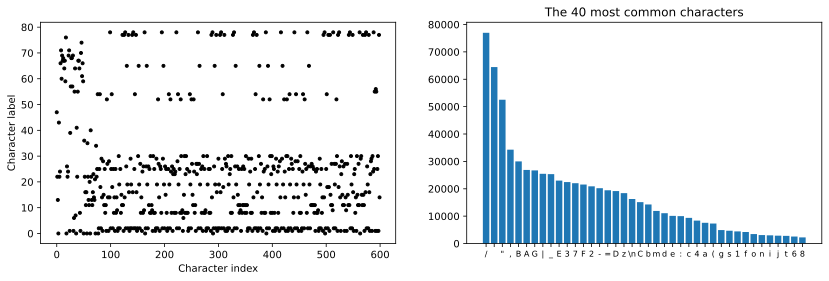

In [12]:
# convert the whole text from characters into numbers
train_data = torch.tensor(encode(train_text), dtype=torch.long)
val_data   = torch.tensor(encode(val_text),   dtype=torch.long)

# let's see the data! (left: the first 600 characters; right: how often each character appears)
fig,axs = plt.subplots(1,2,figsize=(14,4))
axs[0].plot(train_data[:600].numpy(),'k.')
axs[0].set_xlabel('Character index')
axs[0].set_ylabel('Character label')

counts = torch.bincount(train_data, minlength=vocab_size).numpy()
order = np.argsort(counts)[::-1][:40]
axs[1].bar(range(40), counts[order])
axs[1].set_xticks(range(40))
axs[1].set_xticklabels([repr(number2letter[i])[1:-1] for i in order], fontsize=8)
axs[1].set_title('The 40 most common characters')
plt.show()

❓ **Questions**
4. Which characters are the most common? Why is `/` so frequent in jazz solos (and not in folk tunes)?
5. A model that always guesses uniformly among the characters would have a loss of $\ln(\text{vocab size})$. Compute it. We will compare our training loss with this number.

# Part 2 · The model (15 min)

The LSTM in `loremipsum` reads one character at a time and squeezes everything it has read into a hidden state.
A transformer keeps *all* previous characters and, for every new character, asks: **which earlier characters should I look at?**
That's **self-attention**. In jazz ABC, useful things to look at might be: the last chord symbol, the last bar line (to count beats), the same place one chorus ago…

### The heart of the transformer: self-attention in 10 lines

In [13]:
def self_attention(x, Wq, Wk, Wv):
  # x: one vector per character, shape (T, C) = (number of characters, embedding size)
  q = x @ Wq                                      # queries: "what am I looking for?"
  k = x @ Wk                                      # keys:    "what do I contain?"
  v = x @ Wv                                      # values:  "what do I pass on if you pick me?"
  scores = q @ k.T / math.sqrt(k.shape[-1])       # (T, T): how well each query matches each key
  T = x.shape[0]
  mask = torch.tril(torch.ones(T, T)).bool()      # causal mask: True for the past and the present
  scores = scores.masked_fill(~mask, float('-inf'))   # the future gets -inf ...
  weights = F.softmax(scores, dim=-1)             # ... so softmax gives it 0. Each row sums to 1
  return weights @ v, weights                     # each output = weighted average of the values

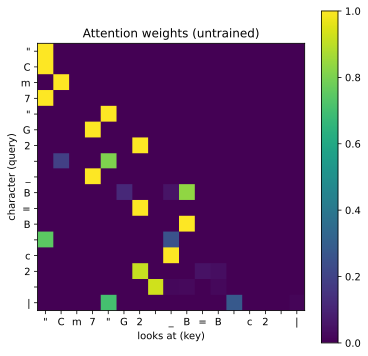

In [14]:
# try it on a little bit of jazz with random (untrained) weights
snippet = '"Cm7"G2 _B=B c2 |'
C = 16                                            # embedding size for this toy example
x = torch.randn(len(snippet), C)                  # random "embeddings", one per character
Wq, Wk, Wv = torch.randn(C, C), torch.randn(C, C), torch.randn(C, C)
out, weights = self_attention(x, Wq, Wk, Wv)

plt.figure(figsize=(6,6))
plt.imshow(weights, cmap='viridis')
plt.xticks(range(len(snippet)), list(snippet))
plt.yticks(range(len(snippet)), list(snippet))
plt.xlabel('looks at (key)')
plt.ylabel('character (query)')
plt.title('Attention weights (untrained)')
plt.colorbar()
plt.show()

❓ **Questions**
6. Why is the upper-right triangle empty? What would go wrong during training without the mask?
7. Each row sums to 1. What does row 0 look like, and why?
8. `self_attention` does not care about the *order* of the characters (try shuffling the rows of `x`). How does the model then know where a character is? (Hint: look for `pos` below.)

### The full model

The real model adds three things around `self_attention`:
* **several heads** working in parallel (each head can look for something different),
* an **MLP** (the feed-forward network from the ANN section) after attention, plus LayerNorm and residual connections: together, one **Block**,
* **embeddings** at the input: a token embedding (which character?) plus a **positional embedding** (where in the context?), and a linear layer at the output that scores each of the `vocab_size` characters.

In [15]:
# meta-parameters
block_size = 256   # context length: how many characters the model can see (≈ 8-10 bars)
n_embd     = 256   # embedding size: each character becomes a vector of 256 numbers
n_head     = 4     # attention heads per block
n_layer    = 4     # number of blocks
dropout    = 0.1   # regularization (see the DUDL regularization section)

In [16]:
class CausalSelfAttention(nn.Module):
  # the self_attention function above, with n_head heads at once and learnable weights
  def __init__(self, n_embd, n_head, block_size, dropout):
    super().__init__()
    self.n_head = n_head
    self.qkv  = nn.Linear(n_embd, 3*n_embd)      # Wq, Wk and Wv in one matrix
    self.proj = nn.Linear(n_embd, n_embd)        # mixes the heads back together
    self.drop = nn.Dropout(dropout)
    self.register_buffer('mask', torch.tril(torch.ones(block_size, block_size)).bool())
    self.att = None                              # we keep the last attention weights for Part 6

  def forward(self, x):
    B, T, C = x.shape                            # batch, time (characters), channels
    q, k, v = self.qkv(x).split(C, dim=2)
    # split the channels into heads: (B, n_head, T, C/n_head)
    q = q.view(B, T, self.n_head, C//self.n_head).transpose(1, 2)
    k = k.view(B, T, self.n_head, C//self.n_head).transpose(1, 2)
    v = v.view(B, T, self.n_head, C//self.n_head).transpose(1, 2)
    scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
    scores = scores.masked_fill(~self.mask[:T, :T], float('-inf'))
    att = F.softmax(scores, dim=-1)
    self.att = att.detach()
    y = self.drop(att) @ v
    y = y.transpose(1, 2).reshape(B, T, C)       # glue the heads back together
    return self.proj(y)


class Block(nn.Module):
  # attention (look around) + MLP (think about it), each with LayerNorm and a residual connection
  def __init__(self, n_embd, n_head, block_size, dropout):
    super().__init__()
    self.ln1  = nn.LayerNorm(n_embd)
    self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
    self.ln2  = nn.LayerNorm(n_embd)
    self.mlp  = nn.Sequential(nn.Linear(n_embd, 4*n_embd), nn.GELU(),
                              nn.Linear(4*n_embd, n_embd), nn.Dropout(dropout))

  def forward(self, x):
    x = x + self.attn(self.ln1(x))
    x = x + self.mlp(self.ln2(x))
    return x


class MusicGPT(nn.Module):
  def __init__(self, vocab_size, block_size=256, n_embd=256, n_head=4, n_layer=4, dropout=0.1, use_pos=True):
    super().__init__()
    self.config = dict(vocab_size=vocab_size, block_size=block_size, n_embd=n_embd,
                       n_head=n_head, n_layer=n_layer, dropout=dropout, use_pos=use_pos)
    self.block_size = block_size
    self.use_pos = use_pos
    self.tok_emb = nn.Embedding(vocab_size, n_embd)      # which character?
    self.pos_emb = nn.Embedding(block_size, n_embd)      # where in the context?
    self.drop    = nn.Dropout(dropout)
    self.blocks  = nn.Sequential(*[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
    self.ln_f    = nn.LayerNorm(n_embd)
    self.head    = nn.Linear(n_embd, vocab_size)         # a score for every possible next character

  def forward(self, idx):
    B, T = idx.shape
    x = self.tok_emb(idx)                                # (B, T, n_embd)
    if self.use_pos:
      x = x + self.pos_emb(torch.arange(T, device=idx.device))
    x = self.blocks(self.drop(x))
    return self.head(self.ln_f(x))                       # (B, T, vocab_size)

In [17]:
# model instance
model = MusicGPT(vocab_size, block_size, n_embd, n_head, n_layer, dropout).to(device)

# count the parameters (see DUDL_ANN_numParameters)
nparams = sum(p.numel() for p in model.parameters())
print(f'MusicGPT: {nparams:,} parameters')
for name, part in [('token embedding', model.tok_emb), ('positional embedding', model.pos_emb),
                   ('one block', model.blocks[0]), ('output layer', model.head)]:
  print(f'  {name:22s} {sum(p.numel() for p in part.parameters()):>10,}')

# for comparison: the LSTM of DUDL_RNN_loremipsum (hidden_size=512, num_layers=3) on our vocabulary
lstm = nn.LSTM(vocab_size, 512, 3)
print(f'\nloremipsum LSTM: {sum(p.numel() for p in lstm.parameters()):,} parameters')

MusicGPT: 3,265,615 parameters
  token embedding            20,224
  positional embedding       65,536
  one block                 789,760
  output layer               20,303

loremipsum LSTM: 5,416,960 parameters


❓ **Questions**
9. Where are most of the parameters? Compute by hand the parameters of one block (hint: `qkv` is 256×768 + 768, the MLP is 256×1024 + 1024 + 1024×256 + 256, plus `proj` and two LayerNorms).
10. The loremipsum LSTM is even bigger than our GPT. Which one do you expect to train faster on a GPU, and why? (Think: can an LSTM process the 256 characters of a sequence in parallel?)

# Part 3 · Training (15–20 min, GPU)

Same recipe as `loremipsum`: input `x` = a piece of text, target `y` = the same piece **shifted by one character**, `CrossEntropyLoss`, Adam. Two differences:
* we take a **batch of 64 random pieces** of 256 characters at a time, instead of walking through the text;
* thanks to the causal mask, the model predicts **all 256 next characters in parallel** in one forward pass.

**Perplexity** = $e^{\text{loss}}$: "the model is as unsure as if it had to choose between *N* equally likely characters". Uniform guessing gives *N* = vocab size.

In [18]:
def get_batch(data, batch_size=64, block_size=256):
  # random starting points, then input x and target y (shifted version of x, as in loremipsum)
  ix = torch.randint(len(data) - block_size - 1, (batch_size,))
  x = torch.stack([data[i   : i+block_size  ] for i in ix])
  y = torch.stack([data[i+1 : i+block_size+1] for i in ix])
  return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(model, data, n_batches=20):
  # average loss over some random batches, with dropout switched off
  model.eval()
  losses = []
  for _ in range(n_batches):
    x, y = get_batch(data, 64, model.block_size)
    logits = model(x)
    losses.append(F.cross_entropy(logits.view(-1, logits.shape[-1]), y.view(-1)).item())
  model.train()
  return float(np.mean(losses))                # a plain Python number (safe to save with torch.save)

x, y = get_batch(train_data, batch_size=2, block_size=40)
print('x:', repr(decode(x[0])))
print('y:', repr(decode(y[0])))

x: 'e/=d/- "C#m7"d/^d/A "F#7"A^D|"Bmaj7"DA,/'
y: '/=d/- "C#m7"d/^d/A "F#7"A^D|"Bmaj7"DA,/G'


In [19]:
def save_run(path, model, checkpoints, losses):
  torch.save(dict(config=model.config, vocab=uniquecharacters, checkpoints=checkpoints, losses=losses), path)

def train_model(model, max_steps=3000, batch_size=64, learning_rate=1e-3,
                save_steps=(), run_name='music_gpt', eval_every=100, plot_every=250):
  lossfun   = nn.CrossEntropyLoss()
  optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
  losses = dict(step=[], train=[], val=[])
  checkpoints = {}
  t0 = time.time()

  for step in range(1, max_steps+1):
    # get input and target (shifted version of input)
    x, y = get_batch(train_data, batch_size, model.block_size)

    # forward pass and loss: every position predicts its next character
    logits = model(x)                                   # (batch, block_size, vocab_size)
    loss = lossfun(logits.view(-1, logits.shape[-1]), y.view(-1))

    # backprop
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # from time to time: measure train and validation loss
    if step % eval_every == 0 or step == 1:
      losses['step'].append(step)
      losses['train'].append(estimate_loss(model, train_data))
      losses['val'].append(estimate_loss(model, val_data))

    # keep a copy of the weights at some steps (and save them, in case Colab disconnects)
    if step in save_steps:
      checkpoints[step] = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
      save_run(os.path.join(SAVE_DIR, run_name + '.pt'), model, checkpoints, losses)

    # live plot
    if step % plot_every == 0 or step == max_steps:
      clear_output(wait=True)
      plt.figure(figsize=(8,4))
      plt.plot(losses['step'], losses['train'], label='train')
      plt.plot(losses['step'], losses['val'], label='validation')
      plt.axhline(np.log(vocab_size), color='gray', linestyle='--', label='uniform guessing')
      plt.xlabel('Training step'); plt.ylabel('Loss'); plt.legend(); plt.ylim(0, 5)
      plt.title(f'step {step}/{max_steps} · val loss {losses["val"][-1]:.3f} · '
                f'perplexity {np.exp(losses["val"][-1]):.2f} · {time.time()-t0:.0f} s')
      plt.show()

  return losses, checkpoints

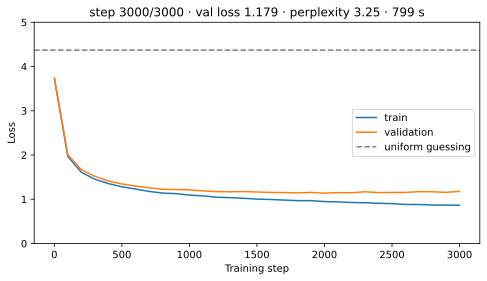

In [20]:
#@title Train (≈ 10 min on a T4 GPU)
TRAIN = True        #@param {type:"boolean"}
max_steps = 3000    #@param {type:"integer"}
save_steps = [200, 1000, 3000]
RUN_NAME = 'e2_jazz_gpt'

if TRAIN:
  torch.manual_seed(0)
  model = MusicGPT(vocab_size, block_size, n_embd, n_head, n_layer, dropout).to(device)
  losses, checkpoints = train_model(model, max_steps=max_steps, save_steps=save_steps, run_name=RUN_NAME)

**No GPU / training failed?** Use the teacher's checkpoint: set `TRAIN = False` above, then run the next cell.
It loads `e2_jazz_gpt.pt` from your `SAVE_DIR` (put it there via Drive) or downloads it from `FALLBACK_URL`.

In [21]:
#@title Load a saved run (your own, or the teacher's fallback)
FALLBACK_URL = ''   #@param {type:"string"}

def load_run(path):
  global uniquecharacters, number2letter, letter2number, vocab_size
  run = torch.load(path, map_location='cpu')
  if run['vocab'] != uniquecharacters:      # make sure we use the vocabulary the model was trained with
    print('Using the vocabulary stored in the checkpoint.')
    uniquecharacters = run['vocab']
    number2letter = dict(enumerate(uniquecharacters))
    letter2number = { l:i for i,l in number2letter.items() }
    vocab_size = len(uniquecharacters)
  model = MusicGPT(**run['config']).to(device)
  model.load_state_dict(run['checkpoints'][max(run['checkpoints'])])
  return model, run['checkpoints'], run['losses']

if not TRAIN:
  path = os.path.join(SAVE_DIR, RUN_NAME + '.pt')
  if not os.path.exists(path) and FALLBACK_URL:
    urllib.request.urlretrieve(FALLBACK_URL, path)
  model, checkpoints, losses = load_run(path)
  print('Loaded checkpoints at steps', sorted(checkpoints))

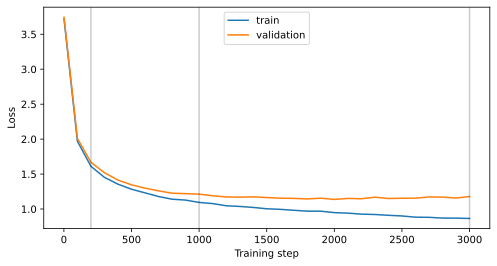

final validation loss 1.179 → perplexity 3.25 (uniform guessing: 79)


In [22]:
# check out the losses
plt.figure(figsize=(8,4))
plt.plot(losses['step'], losses['train'], label='train')
plt.plot(losses['step'], losses['val'], label='validation')
for s in sorted(checkpoints):
  plt.axvline(s, color='k', alpha=.2)
plt.xlabel('Training step'); plt.ylabel('Loss'); plt.legend()
plt.show()
print(f'final validation loss {losses["val"][-1]:.3f} → perplexity {np.exp(losses["val"][-1]):.2f} '
      f'(uniform guessing: {vocab_size})')

❓ **Questions**
11. Compare the first loss with $\ln(\text{vocab size})$ from question 5. Why does training start there?
12. A perplexity of about 3 means: on average the model hesitates between ~3 characters. Where in a jazz ABC line is the next character easy to guess, and where is it hard?
13. Is the model overfitting (validation loss going up while training loss goes down)? What could you change if it were?

# Part 4 · The learning curve you can hear (30 min)

`generate` writes music one character at a time: run the model, turn the scores of the **next** character into probabilities, roll the dice, append the character, repeat. (`loremipsum` always took the most likely character, `argmax`; here we sample.)

In [23]:
@torch.no_grad()
def generate(model, prompt, max_new_chars=1200, temperature=1.0, top_k=None):
  model.eval()
  idx = torch.tensor([encode(prompt)], device=device)
  out = prompt
  for _ in range(max_new_chars):
    logits = model(idx[:, -model.block_size:])     # only the last block_size characters fit
    logits = logits[0, -1, :] / temperature        # scores of the NEXT character, reshaped by the temperature
    if top_k is not None:                          # keep only the k best candidates
      kth_best = torch.topk(logits, top_k).values[-1]
      logits[logits < kth_best] = -float('inf')
    probs = F.softmax(logits, dim=-1)              # scores -> probabilities
    next_char = torch.multinomial(probs, 1)        # roll the dice
    idx = torch.cat([idx, next_char.view(1, 1)], dim=1)
    out += number2letter[next_char.item()]
    if out.endswith('|]') or out.endswith('\n\n'): # end of the chorus
      break
    if out.endswith('\nX:'):                      # the model started a new tune: stop before it
      out = out[:-3]
      break
  model.train()
  return out

def report(tune):
  c = check_abc(tune)
  print(f"{c['n_bars']} bars · {100*c['bar_ok']:.0f}% with the right length · "
        f"{c['errors']} invalid characters · finished: {c['finished']}")

In [24]:
prompt = make_prompt(soloist='Charlie Parker (as)', style='bebop, swing', tempo=200, key='Bb', title='Blues for E2')
print(prompt)

for step in sorted(checkpoints):
  model.load_state_dict(checkpoints[step])
  torch.manual_seed(1)
  tune = generate(model, prompt, temperature=0.8)
  print(f'\n================  step {step}  ================')
  print(tune[len(prompt):][:500])
  report(tune)
  show_abc(tune, midi_name=f'step{step}')

X:1
T:Blues for E2
C:Charlie Parker (as)
R:bebop, swing
M:4/4
L:1/8
Q:1/4=200
K:Bb




================  step 200  ================
"Bb7"c _A F FB|E2 A3/BFE2- F2 E2/z/|z6 zB,/=B,/- z2 A|"Fm"_G2- A2 A/_A/- "Ebm7b9"_G/z3/ z2|
"Fm7"z2 =B/A/A/ (3:2:2C2 B2|"Ab7"C3|"Bb7"B, C2|"G7"B2- B2 B3/A2 _G2|
"Dm7"G3 G2 D B=ED D A|"F69#19#5
10 bars · 0% with the right length · 6 invalid characters · finished: False



================  step 1000  ================
"Bb7"z2 (3EBc d2-|"Eb7"d2- d/z3/ z4|zc'3- c'2- c'2- c'/_g/-|g/fd/- d/c/BA/- AB (3_GFA-|
"Bb7"A/BA/- A/BA/- A/=A/B/A/ A/Bc/|(3"Eb7"ABA =A/_G/G/A/ B/c/G/E/ _G/=G/F/|"Bb7"B^F D/B,/D "Eb7"F/G/E/ (3=EGB-|"Ab7"B/=AB/- B=A BA/=B/A/|
"Gm7"G=d ef e/e/g/-|"C7"g/f/f/ _g2 e/_d/=B/|"F7"c/B3/- B_A B/B/A/_G/|"Bb7"F/E3- E/z3/ z2|]
12 bars · 17% with the right length · 0 invalid characters · finished: True



================  step 3000  ================
"Bb7"z2 F2 FF GF|"Eb7"FE3/FF/- F/E_D/ B,B,-|"Bb7"B,2 F,_A, B,A, B,A,|"Eb7"G,F, B,_D =DE F_A|
"Bb7"G_A FG AF GF|"Bb7"_AF DC B,C DF|"Eb7"B=B, G,A, B,_D =D_D|"Bb7"DF A_G F=E DC|B,=B, C2 B,C =EG|
"Cm7"FE DC =B,A, G,A,|"F7"G,B, A,_A, =A,_G, F,E,|"Bb7"D,F, A,F, B,z3|]
12 bars · 100% with the right length · 0 invalid characters · finished: True


❓ **Questions** (listen first, then answer)
14. Step 200: what has the model already learned? (characters? bar lines? chord symbols?) What is missing?
15. Step 1000 vs step 3000: does it get the bar length right? Does it follow the chord symbols (do the notes fit the chords)? Does it end the chorus?
16. In which order did the model learn these things? Why do you think the "easy" things come first?

# Part 5 · Sampling: temperature, top-k, your own prompt (30 min)

* **temperature** < 1 makes the likely characters even more likely (safe, repetitive); > 1 flattens the distribution (adventurous, more mistakes).
* **top-k** only allows the *k* most likely characters (cuts off the long tail of nonsense).
* The **prompt** is everything the model reads before writing. The header lines are a kind of *conditioning*: we will look at this properly in E3.

In [25]:
model.load_state_dict(checkpoints[max(checkpoints)])   # the last checkpoint

for temperature in [0.5, 0.8, 1.2]:
  torch.manual_seed(2)
  tune = generate(model, prompt, temperature=temperature)
  print(f'\n================  temperature {temperature}  ================')
  report(tune)
  show_abc(tune, midi_name=f'temp{temperature}')


================  temperature 0.5  ================
43 bars · 93% with the right length · 0 invalid characters · finished: False



================  temperature 0.8  ================
25 bars · 76% with the right length · 0 invalid characters · finished: False



================  temperature 1.2  ================
47 bars · 83% with the right length · 5 invalid characters · finished: False


In [26]:
#@title Your prompt
soloist = 'John Coltrane (ts)'   #@param ['Charlie Parker (as)', 'John Coltrane (ts)', 'Sonny Rollins (ts)', 'Miles Davis (tp)', 'Clifford Brown (tp)', 'Chet Baker (tp)', 'Dexter Gordon (ts)', 'Stan Getz (ts)', 'Lee Konitz (as)', 'Michael Brecker (ts)', 'Pat Metheny (g)', 'J.J. Johnson (tb)'] {allow-input: true}
style = 'hardbop, swing'         #@param ['traditional, twobeat', 'swing era, swing', 'bebop, swing', 'cool, swing', 'hardbop, swing', 'postbop, swing', 'postbop, latin', 'fusion, funk'] {allow-input: true}
key = 'Eb'                       #@param ['C', 'F', 'Bb', 'Eb', 'Ab', 'Db', 'G', 'D', 'Cm', 'Fm', 'Gm', 'Dm'] {allow-input: true}
tempo = 180                      #@param {type:"slider", min:60, max:320, step:10}
title = 'Blues for E2'           #@param {type:"string"}
first_bars = '"Eb7"B2 GB cB GF|"Ab7"' #@param {type:"string"}
temperature = 0.8                #@param {type:"slider", min:0.1, max:2.0, step:0.1}
top_k = 0                        #@param {type:"integer"}

my_prompt = make_prompt(soloist, style, tempo, key, title, first_bars)
tune = generate(model, my_prompt, temperature=temperature, top_k=top_k if top_k > 0 else None)
print(tune)
report(tune)
show_abc(tune, midi_name='my_tune')

X:1
T:Blues for E2
C:John Coltrane (ts)
R:hardbop, swing
M:4/4
L:1/8
Q:1/4=180
K:Eb
"Eb7"B2 GB cB GF|"Ab7"EF GB c_d cB|"Db7"B=A _A=G/B/- B/=A_G/- G/DG/-|(3"Gb7"G=GA G_G FE B,_D|"Emaj7"D3/=B,/- B,/A,/G,/=E,/- E,z3|
"Am7"z4 D/=DE/- ED|"D7"=E_G =G=A3 GG|"Gmaj7"=AF =DB, G,=E, D,_G,|"Daj7"=B,,2- B,,/z3/ z4|
"G7"z4 z=A, B,D|"C7"=EG =AB3 GF|=ED C=B, CE B,=A,|"C7"G,=E,2F, =E,D,|
(3"Fm7"C,=B,=A,- A,2 D=A,3|"Bb7"F,A, B,C DE FG|A=B _B2 =B/z3/ z2|"Ebmaj7"z6 zA|GF E=D _DF ED|
"Abmaj7"CB,2A, (3=B,CD EC|=B,C D=D EF GA|"Gm7b5"A2- A3/=E/- (3EF_G =A_G|"C7b9"FD B,A, G,A,3/B,A,/|
"Fmaj7"A,B, =B,C D=D EF|GB AG F=E _EF|"Fm7"EF B=B, ED CE|"Bbm7"DF GF =EG Bd|
"Eb7"=B2 dd B2 _B=B|"Abmaj7"=AF G2 F2 G=D|z2 FG3 z2|"Abm"zF- (3F=DF AF _D=D|
"Fm7"CB, A,G, A,2 F,A,|G,/F,/G,/F,/- F,2 z2 A,2|z4 A,2 =B,C|"Dbm7"D2 B,=B, C2 D2|
"Gb7"B,3G, A,4-|"Ab6"A,3/z/ z4 zG/A/-|"Fm7"A2- A3/z/ z2 =A=G3/_G/E/-|
"Bbm7"E3/D/- DC FA3|"Eb7"B3G2A B2-|"Ab6"B3/A/- AA =B=B3-|"Db7"=B/z3/ z2 A=B d2|
"Gm7b5"Bd B2 B2 F2|"C7b9"=E2 B,3/z/ z2|"Fm7"zB,

❓ **Questions**
17. At temperature 0.5, 0.8 and 1.2: which is the most *musical*? Which has the most *valid bars*? Are these the same?
18. Try `top_k = 5` with `temperature = 1.2`. Does top-k "repair" the high temperature?
19. Write your own first bar (a lick you like, with a chord symbol) in `first_bars`. Does the model continue in the same style? Does it keep the chord changes going?
20. Change only the soloist (same key, tempo, style). Can you *hear* a difference? Change the title to `Giant Steps` or `Anthropology`. What happens to the chord changes, and why?

# Part 6 · Look inside: attention maps (20 min)

Every head of every block has an attention matrix like the toy one in Part 2. Let's feed a chorus the model has **never seen** (from the validation set) and look for heads with a musical job:
* **bar-line heads**: when the model writes `|`, does it look at the previous `|`? (counting the beats in the bar)
* **harmony heads**: when the model writes a note, does it look at the current chord symbol?

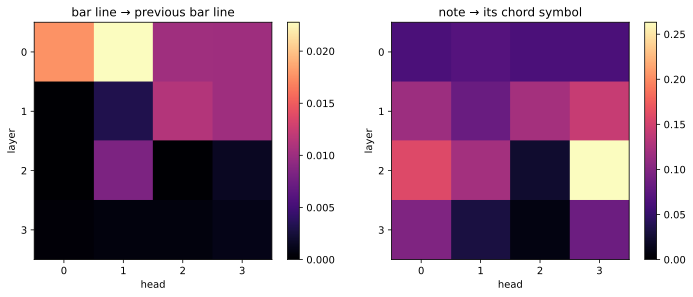

best bar-line head (layer, head): (0, 1)
best harmony head  (layer, head): (2, 3)


In [27]:
# run the model on the first block_size characters of a validation chorus
tune = val_tunes[3]
body_start = tune.index('K:')
window = tune[body_start : body_start + model.block_size]
model.eval()
with torch.no_grad():
  model(torch.tensor([encode(window)], device=device))
att = torch.stack([blk.attn.att[0] for blk in model.blocks]).cpu()   # (n_layer, n_head, T, T)
T = len(window)

# where are the bar lines and the chord symbols?
bars = [i for i, c in enumerate(window) if c == '|']
chord_of = np.full(T, -1)                     # for each position: start of the last chord symbol
spans = [(m.start(), m.end()) for m in re.finditer(r'"[^"]*"', window)]
for s, e in spans:
  chord_of[e:] = s
notes = [i for i, c in enumerate(window) if c in 'ABCDEFGabcdefg' and chord_of[i] >= 0 and
         not any(s <= i < e for s, e in spans)]

# score of each head: attention from a bar line to the previous bar line,
# and from a note to (all characters of) its chord symbol
bar_score = np.zeros(att.shape[:2]); chord_score = np.zeros(att.shape[:2])
for l in range(att.shape[0]):
  for h in range(att.shape[1]):
    A = att[l, h].numpy()
    bar_score[l, h] = np.mean([A[b2, b1] for b1, b2 in zip(bars[:-1], bars[1:])])
    chord_score[l, h] = np.mean([A[i, chord_of[i]:window.index('"', chord_of[i]+1)+1].sum() for i in notes])

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, S, name in zip(axs, [bar_score, chord_score], ['bar line → previous bar line', 'note → its chord symbol']):
  im = ax.imshow(S, cmap='magma', vmin=0)
  ax.set_xlabel('head'); ax.set_ylabel('layer'); ax.set_title(name)
  ax.set_xticks(range(S.shape[1])); ax.set_yticks(range(S.shape[0]))
  plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()
print('best bar-line head (layer, head):', tuple(int(i) for i in np.unravel_index(bar_score.argmax(), bar_score.shape)))
print('best harmony head  (layer, head):', tuple(int(i) for i in np.unravel_index(chord_score.argmax(), chord_score.shape)))

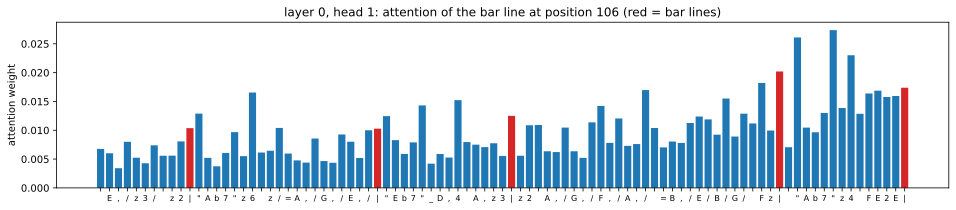

In [28]:
#@title Where does one head look while the model writes a bar line?
layer = -1     #@param {type:"integer"}
head = -1      #@param {type:"integer"}
which_bar = 4  #@param {type:"integer"}
# -1 = use the best bar-line head found above
if layer < 0 or head < 0:
  layer, head = np.unravel_index(bar_score.argmax(), bar_score.shape)

q = bars[which_bar]
A = att[layer, head, q, :q+1].numpy()
start = max(0, q - 90)
plt.figure(figsize=(16, 3))
plt.bar(range(start, q+1), A[start:], color=['C3' if window[i] == '|' else 'C0' for i in range(start, q+1)])
plt.xticks(range(start, q+1), list(window[start:q+1]), fontsize=8)
plt.title(f'layer {layer}, head {head}: attention of the bar line at position {q} (red = bar lines)')
plt.ylabel('attention weight')
plt.show()

❓ **Questions**
21. Use the scores to pick a layer and head. Does the "bar-line head" really look at the previous `|`? Or at something else (the last space = the last beat? the chord?)
22. Find the harmony head and plot it for a note instead of a bar line (change `q`). Which characters of the chord symbol does it use?
23. Attention maps are a nice story, but are they an *explanation*? What else would you need to show that this head really counts beats?

# ★ Code challenges (optional)

Each retraining takes about as long as Part 3. Use `max_steps=1500` to save time, and compare with your Part 3 losses at step 1500.

**1. Context length.** Train a model with `block_size=32` (about one bar). Can it keep the bar length right? Does it keep the chord progression going? Does it end the chorus?

In [29]:
# 1) context length 32 vs 256
# model32 = MusicGPT(vocab_size, block_size=32).to(device)
# losses32, ckpts32 = train_model(model32, max_steps=1500, save_steps=[1500], run_name='ctx32')
# tune = generate(model32, prompt, temperature=0.8); report(tune); show_abc(tune)

**2. LSTM vs Transformer.** The LSTM from `loremipsum`, with `batch_first=True` so it takes our batches, and an embedding of 256 like our GPT. Compare the validation loss at the same step, the time per step, and the samples.

In [30]:
class lstmnet(nn.Module):
  def __init__(self, vocab_size, emb_size=256, hidden_size=512, num_layers=2, block_size=256):
    super().__init__()
    self.config = dict(vocab_size=vocab_size, emb_size=emb_size, hidden_size=hidden_size,
                       num_layers=num_layers, block_size=block_size)
    self.block_size = block_size                   # only used by get_batch and generate
    self.embedding = nn.Embedding(vocab_size, emb_size)
    self.lstm = nn.LSTM(emb_size, hidden_size, num_layers, batch_first=True)
    self.out = nn.Linear(hidden_size, vocab_size)

  def forward(self, x):
    y, h = self.lstm(self.embedding(x))
    return self.out(y)

# lstm = lstmnet(vocab_size).to(device)
# print(f'{sum(p.numel() for p in lstm.parameters()):,} parameters')
# losses_lstm, ckpts_lstm = train_model(lstm, max_steps=1500, save_steps=[1500], run_name='lstm')
# tune = generate(lstm, prompt, temperature=0.8); report(tune); show_abc(tune)

**3. No positional embedding.** `MusicGPT(..., use_pos=False)`. The model has no idea *where* a character is, only *what* came before (through the mask). What happens to the bar structure? (Open question: results vary between runs. Why might the causal mask alone still give some position information?)

In [31]:
# 3) no positional embedding
# model_nopos = MusicGPT(vocab_size, use_pos=False).to(device)
# losses_nopos, ckpts_nopos = train_model(model_nopos, max_steps=1500, save_steps=[1500], run_name='nopos')

**4. Memorization check.** Is the model copying the training set? `longest_common_substring(sample, train_text)` finds the longest piece of a sample that appears in the training text. **Compare with real music**: unseen validation choruses also share fragments with the training set (jazz players reuse licks, and many tunes share chord changes).

In [32]:
# 4) memorization check
model.load_state_dict(checkpoints[max(checkpoints)])
torch.manual_seed(3)
sample = abc_body(generate(model, prompt, temperature=0.8))
copied = longest_common_substring(sample, train_text)
print(f'generated: longest copied fragment = {len(copied)} characters, {copied.count("|")} bar lines:\n  {copied!r}')

# baseline: real choruses the model has never seen
for t in val_tunes[:3]:
  c = longest_common_substring(abc_body(t)[:800], train_text)
  print(f'real (validation): {len(c)} characters')

generated: longest copied fragment = 19 characters, 1 bar lines:
  'D|"Cm7"CD E=E "F7"F'
real (validation): 14 characters
real (validation): 16 characters
real (validation): 14 characters


# H2 · Home: the sampling lab (1.5 h)

2 checkpoints × 3 temperatures × 5 samples = 30 tunes. For each setting the table gives:
* **valid %**: tunes with no invalid characters and at least 4 bars,
* **bars ok %**: bars with the right duration for 4/4,
* **finished %**: tunes that end the chorus with `|]`,
* **longest copy**: the longest fragment copied from the training set (characters).

All samples are saved to `SAVE_DIR/h2_samples.abc` (open it in any ABC tool, or use `show_abc` below).

In [33]:
def sampling_lab(steps=(1000, 3000), temperatures=(0.5, 0.8, 1.2), n_samples=5, prompt=prompt, top_k=None):
  rows, samples = [], []
  for step in steps:
    model.load_state_dict(checkpoints[step])
    for temp in temperatures:
      for i in range(n_samples):
        tune = generate(model, prompt, temperature=temp, top_k=top_k)
        c = check_abc(tune)
        copy = longest_common_substring(abc_body(tune), train_text)
        rows.append(dict(step=step, temperature=temp, sample=len(samples),
                         valid=(c['errors'] == 0 and c['n_bars'] >= 4), bars_ok=c['bar_ok'],
                         finished=c['finished'], n_bars=c['n_bars'], longest_copy=len(copy)))
        samples.append(re.sub(r'^X:.*', f'X:{len(samples)}', tune, count=1))
  with open(os.path.join(SAVE_DIR, 'h2_samples.abc'), 'w') as f:
    f.write('\n\n'.join(samples) + '\n')
  df = pd.DataFrame(rows)
  table = df.groupby(['step', 'temperature']).agg(valid_pct=('valid', 'mean'), bars_ok_pct=('bars_ok', 'mean'),
                                                  finished_pct=('finished', 'mean'),
                                                  longest_copy=('longest_copy', 'mean'))
  table[['valid_pct', 'bars_ok_pct', 'finished_pct']] *= 100
  return table.round(1), df, samples

table, lab_df, lab_samples = sampling_lab()      # ≈ 5-10 min on a T4
table

valid_pct  bars_ok_pct  finished_pct  longest_copy
step temperature                                                    
1000 0.5               60.0         22.2          40.0          16.4
     0.8               60.0         31.3          80.0          16.4
     1.2               80.0         52.0          80.0          15.8
3000 0.5              100.0         78.0          20.0          18.8
     0.8               80.0         91.0          80.0          18.0
     1.2               80.0         90.8         100.0          14.6

In [34]:
# listen to any sample: the number is the 'sample' column of lab_df
print(lab_df.loc[lab_df['sample'] == 0])
show_abc(lab_samples[0])

   step  temperature  sample  valid  bars_ok  finished  n_bars  longest_copy
0  1000          0.5       0  False     0.04     False      25            17


### Listening log (copy into your report)

| sample | step | temperature | musical? (1–5) | follows the changes? (1–5) | comment |
|---|---|---|---|---|---|
| | | | | | |

**Hand in:** the table above, your listening log, the **best and the worst** sample (ABC text + MIDI from the download link), and 5 lines explaining what the numbers and your ears tell you. Do the metrics agree with your ears? Is there a setting that is valid but boring?

---
### Teacher notes
* **Data:** `build_dataset()` turns `wjazzd.db` (Weimar Jazz Database v2.1, ODbL) into ~1,250 ABC choruses in a few seconds; the result is cached as `SAVE_DIR/jazz_abc.txt`. If the Jazzomat server is down, put `jazz_abc.txt` in the students' `SAVE_DIR` before class.
* **Fallback checkpoint:** `e2_jazz_gpt.pt` holds the checkpoints at steps 200 / 1000 / 3000, the vocabulary and the loss curves. Share it on Drive (students copy it to `SAVE_DIR`) or paste a direct download link into `FALLBACK_URL`.
* **Playback** uses [abcjs](https://www.abcjs.net/) in the browser (sheet + swing + chords + MIDI download), so no `apt install` is needed.
* **Measured on an Apple M1 Pro (MPS):** 3,000 steps ≈ 14 min; the H2 lab ≈ 5 min. A free T4 should be similar or faster: **check both in a dry run**, and check that the abcjs *Download MIDI* link works inside Colab's output frame.
* **Expected results** (dropout 0.1, measured on 20 samples at temperature 0.8): validation loss ≈ 1.15–1.18 (perplexity ≈ 3.2); bars with the right length ≈ 0–5 % at step 200, 20–60 % at step 1,000, ≈ 90 % at step 3,000. The validation loss flattens after ~2,000 steps while the training loss keeps going down: a good moment to talk about overfitting (question 13). With the title `Blues for E2` the model usually writes blues changes: the title already works as a control (question 20, and E3).